# Práctica 4. Primeros circuitos cuánticos con Qiskit

**Duración estimada:** 60–75 minutos   
**Herramientas:** Python, NumPy, Qiskit, Qiskit Aer y Matplotlib

> Completa las celdas marcadas con `TODO` y responde razonadamente en las celdas Markdown. Ejecuta al terminar **Kernel → Restart & Run All**.

## Objetivos

- Crear y visualizar circuitos de uno y dos qubits.
- Diferenciar qubits, bits clásicos, puertas y medidas.
- Preparar $|0\rangle$ y $|1\rangle$.
- Obtener amplitudes y probabilidades exactas con `Statevector`.
- Transpilar y ejecutar circuitos con `AerSimulator`.
- Obtener conteos, frecuencias e histogramas.
- Distinguir simulación exacta y muestreo.
- Interpretar el orden de bits de Qiskit.
- Comparar Qiskit con el formalismo matricial de NumPy.

## Entrega

Entrega este notebook con el nombre:

```text
04_primeros_circuitos_qiskit_apellidos_nombre.ipynb
```

Debe contener código ejecutado, circuitos dibujados, resultados, respuestas, pruebas y una conclusión final. No se aceptarán respuestas compuestas únicamente por código.

# Preparación del entorno

## Ejercicio 1. Instalación y comprobación

Si el entorno no dispone de las bibliotecas, descomenta y ejecuta la siguiente celda una sola vez. Reinicia después el kernel.

In [2]:
# Descomenta únicamente si necesitas instalar las dependencias.
# %pip install qiskit qiskit-aer matplotlib pylatexenc matplotlib

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
import qiskit_aer

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

np.set_printoptions(precision=5, suppress=True)

# TODO: muestra las versiones de Qiskit, Qiskit Aer y NumPy
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("NumPy:", np.__version__)


Qiskit: 2.5.2
Qiskit Aer: 0.17.2
NumPy: 2.4.6


### Responde

1. ¿Qué funciones aporta Qiskit?

    _qubits, bits clásicos, puertas y medidas_
2. ¿Para qué se utiliza Qiskit Aer?

    _ejecuta circuitos en el ordenador clásico, devolviendo conteos de medidas, y permite simular tanto el caso ideal como modelos de ruido._
3. ¿Por qué puede ser necesario reiniciar el kernel después de instalar?

    _Para recargar la memoria del kernel y pueda encontrar los paquetes instalados_ 
4. ¿Qué biblioteca permite comparar los circuitos con matrices?

    _Numpy, permite representar estados como vectores y puertas como matrices._


# Parte A. Construcción de circuitos

## Ejercicio 2. Circuito vacío de un qubit

Crea un circuito con un qubit, sin bits clásicos ni puertas. Muestra el circuito, el número de qubits y el número de bits clásicos. Visualízalo en texto y con Matplotlib.

Circuito 0:    
q: 
   
Número de qubits: 1
Número de bits clásicos: 0


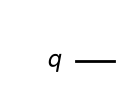

In [4]:
circuito_0 = QuantumCircuit(1) # Crea un circuito cuántico con 1 qubit

# TODO: muestra el objeto y sus propiedades
# TODO: visualiza con draw() y draw("mpl")

print("Circuito 0:",circuito_0)
print("Número de qubits:", circuito_0.num_qubits)
print("Número de bits clásicos:", circuito_0.num_clbits)
display(circuito_0.draw(output="mpl")) # mpl es para usar matplotlib para dibujar el circuito

### Responde

1. ¿Qué estado tiene inicialmente el qubit?
    
    _El estado 0_
2. ¿Un circuito vacío carece de estado?
    
    _No, es un estado 0_
3. ¿Se ha ejecutado al construirlo?

    _No, solo se construye el circuito_
4. ¿Qué diferencia existe entre construir y ejecutar?

    _Al construir se define el qubit y operaciones que componen al circuito. Al ejecutar es simularlo para obtener un resultado._
5. ¿Qué representa la línea horizontal?

    _Representa las operaciones que se ejercen sobre el qubit en orden cronológico_

## Ejercicio 3. Circuito con un bit clásico
Crea un circuito con un qubit y un bit clásico, pero sin medidas. Consulta sus propiedades y visualízalo.

Circuito clásico:      
  q: 
     
c: 2/
     
Número de qubits: 1
Número de bits clásicos: 2


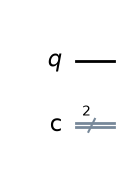

In [5]:
circuito_clasico = QuantumCircuit(1,2) # Crea un circuito cuántico con 1 qubit y 2 bits clásicos

# TODO: muestra num_qubits, num_clbits y el circuito
print("Circuito clásico:",circuito_clasico)
print("Número de qubits:", circuito_clasico.num_qubits)
print("Número de bits clásicos:", circuito_clasico.num_clbits)
display(circuito_clasico.draw(output="mpl")) # mpl es para usar matplotlib para dibujar el circuito

### Responde

1. ¿Qué diferencia presenta respecto al circuito anterior?

    _Aparece una segunda línea doble que es un bit clásico._
2. ¿Declarar un bit clásico mide automáticamente?

    _No, solo reserva espacio para guardar el resultado_
3. ¿Para qué se utilizará el bit clásico?

    _Para almacenar el resultado de medir un qubit._
4. ¿Puede encontrarse en superposición?

    _No_



## Ejercicio 4. Preparación de $|1\rangle$

Crea un circuito de un qubit, aplica $X$ al qubit 0 y visualízalo.

   ┌───┐
q: ┤ X ├
   └───┘


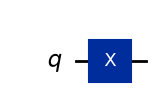

In [6]:
circuito_1 = QuantumCircuit(1)
circuito_1.x(0)  # Aplica la compuerta X al qubit 0
print(circuito_1)
display(circuito_1.draw(output="mpl")) # mpl es para usar matplotlib para dibujar el circuito

### Responde

1. ¿Cuál es el estado inicial?

    _El estado 0_
2. ¿Qué transformación realiza $X$?

    _Cambia las amplitudes de los dos estados que componen al qubit. Esto hace que si empieza con el estado 0 se vuelva el estado 1_
3. ¿Qué estado debe obtenerse?

    _El esatdo 1_
4. ¿Qué indica el argumento de `x(0)`?

    _Indica que se aplica la puerta X en el primer qubit (en este caso solo hay uno)_
5. ¿Qué ocurriría al utilizar `x(1)` en este circuito?

    _Daría error porque estarías intentando aplicar una puerta a un qubit que no existe_

## Ejercicio 5. Dos aplicaciones de $X$
Construye y visualiza un circuito con dos puertas $X$ consecutivas sobre el mismo qubit. Predice el estado final antes de simularlo.

   ┌───┐┌───┐
q: ┤ X ├┤ X ├
   └───┘└───┘


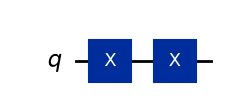

In [7]:
circuito_xx = QuantumCircuit(1)
circuito_xx.x(0)  # Aplica la compuerta X al qubit 0
circuito_xx.x(0)  # Aplica la compuerta X al qubit 0 nuevamente

# TODO: aplica X dos veces y visualiza
print(circuito_xx)
display(circuito_xx.draw(output="mpl")) # mpl es para usar matplotlib para dib

### Responde

1. ¿Cuál debe ser el estado final?

    _El resultado es el mismo que si no hubieramos usado ninguna puerta, es decir, estado 0._
2. ¿Qué relación se cumple entre $X^2$ y la identidad?

    _Cumple que $X^2$ equivale a la identidad._
3. ¿Importa que ambas puertas actúen sobre el mismo qubit?

    _Si, porque sino el resultado es otro. Cada qubit tiene su estado, no se combinan de esa manera._
4. ¿Se aplican simultáneamente?

    _No, una se aplica después de otra._



# Parte B. Vectores de estado

## Ejercicio 6. Estado del circuito vacío

Obtén `Statevector.from_instruction(circuito_0)`. Muestra el objeto, `data`, sus tipos y la forma del array. Compáralo con $|0\rangle=(1,0)^T$.

In [8]:
estado_0 = Statevector.from_circuit(circuito_0)

ket_0_numpy = np.array([1, 0], dtype=complex)

# TODO: muestra la información y compara con np.allclose()
print("Statevector del circuito 0:", estado_0)
print("data;", estado_0.data)
print("Tipo de objeto:", type(estado_0))
print("Tipo de data:", type(estado_0.data))
print("dtype:", estado_0.data.dtype)
print("shape:", estado_0.data.shape)
print("Coincide con ket_0_numpy:", np.allclose(estado_0.data, ket_0_numpy))

Statevector del circuito 0: Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
data; [1.+0.j 0.+0.j]
Tipo de objeto: <class 'qiskit.quantum_info.states.statevector.Statevector'>
Tipo de data: <class 'numpy.ndarray'>
dtype: complex128
shape: (2,)
Coincide con ket_0_numpy: True


### Responde

1. ¿Qué diferencia existe entre `Statevector` y `data`?

    _`Statevector` es de Qiskit y es un objeto que representa el estado cuántico. `data`es de numpy y es un array con las amplitudes._
2. ¿Cuántas amplitudes contiene un qubit?

    _Dos_
3. ¿Por qué son complejas?

    _Porque en cuántica las amplitudes son complejas, al representarlo en computación se mantiene para hacer una representación lo más fiel posible_
4. ¿Por qué se utiliza `np.allclose()`?

    _Porque la computación tiene límites de decimales, y a veces en papel es un número entero pero en el ordenador por los calculos que ha hecho no._



## Ejercicio 7. Estado después de $X$
Obtén el vector de `circuito_1`. Muestra norma, amplitudes y probabilidades. Compáralo con $|1\rangle=(0,1)^T$.

In [9]:
estado_1 = Statevector.from_circuit(circuito_1)
# estado_1.x(0)  # Aplica la compuerta X al qubit 0
ket_1_numpy = np.array([0, 1], dtype=complex)

# TODO: muestra vector, norma, amplitudes y probabilidades
# TODO: compara con ket_1_numpy
print("Statevector del circuito 1:", estado_1)
print("data;", estado_1.data)
print("Tipo de objeto:", type(estado_1))
print("Tipo de data:", type(estado_1.data))
print("dtype:", estado_1.data.dtype)
print("shape:", estado_1.data.shape)
print("Coincide con ket_1_numpy:", np.allclose(estado_1.data, ket_1_numpy))

Statevector del circuito 1: Statevector([0.+0.j, 1.+0.j],
            dims=(2,))
data; [0.+0.j 1.+0.j]
Tipo de objeto: <class 'qiskit.quantum_info.states.statevector.Statevector'>
Tipo de data: <class 'numpy.ndarray'>
dtype: complex128
shape: (2,)
Coincide con ket_1_numpy: True


### Responde

1. ¿Qué amplitud tiene cada estado de la base?

    _En este caso, que elqubit ha sido sometido a una puerta X anteriormente es de: $|0\rangle$ tiene amplitud 0 y $|1\rangle$ tiene amplitud 1._
2. ¿Qué probabilidad tiene cada resultado?

    _.$P(0) = |0|^2 = 0$ y $P(1) = |1|^2 = 1$._
3. ¿Se necesitan shots para obtener este vector?

    _No, Statevector hace un cálculo exacto del estado. No estamos colapsando el qubit_
4. ¿Se ha realizado una medida?

    _No, el vector se obtiene matemáticamente no por resultados._



## Ejercicio 8. Estado después de dos $X$
Obtén el estado exacto de `circuito_xx` y comprueba que coincide con $|0\rangle$.

In [10]:
estado_xx = Statevector.from_circuit(circuito_xx)

# TODO: muestra el estado y comprueba la igualdad
print("Vector xx:", estado_xx)
print("data;", estado_xx.data)
print("Coincide con el estado 0:", np.allclose(estado_xx.data, ket_0_numpy))

Vector xx: Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
data; [1.+0.j 0.+0.j]
Coincide con el estado 0: True


### Responde

1. ¿Ha cambiado el circuito aunque coincida el estado final?

    _Si, por lo dicho, aplicar dos puertas X es equivalente a la I_
2. ¿Es igual un circuito vacío a otro con dos puertas $X$?

    _No, aunque el estado resultante sea el mismo_
3. ¿Puede deducirse toda la secuencia observando solo el estado final?

    _No, hay infinitos circuitos que dan el mismo estado final._

## Ejercicio 9. Probabilidades exactas

Para los tres estados anteriores, muestra `probabilities()` y `probabilities_dict()` y construye una tabla comparativa.

In [11]:
estado_0= QuantumCircuit(1)
estado_1= QuantumCircuit(1)
estado_1.x(0) 
estado_xx= QuantumCircuit(1)
estado_xx.x(0)  
estado_xx.x(0)  



estados_exactos = {
    "Vacío": estado_0,
    "Una X": estado_1,
    "Dos X": estado_xx,
}   


# TODO: muestra vector y probabilidades para cada estado
for nombre, circuito in estados_exactos.items():
    estado = Statevector.from_circuit(circuito)
    print(f"Estado: {nombre}")
    print("Vector:", estado)
    print("Probabilidades:", estado.probabilities())
    print()

Estado: Vacío
Vector: Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
Probabilidades: [1. 0.]

Estado: Una X
Vector: Statevector([0.+0.j, 1.+0.j],
            dims=(2,))
Probabilidades: [0. 1.]

Estado: Dos X
Vector: Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
Probabilidades: [1. 0.]



### Responde

1. ¿Por qué el diccionario puede omitir resultados de probabilidad cero?

    _Porque solo incluye los resultados con probabilidad no nula. Con muchos qubits hay $2^n$ resultados posibles y la mayoría pueden tener probabilidad cero, así que omitirlos ahorra memoria y facilita la lectura_
2. ¿Son probabilidades exactas o experimentales?

    _Exactas, calculadas con la regla de Born_
3. ¿Contienen toda la información del estado?

    _No, se pierde la fase_
4. ¿Puede reconstruirse la fase solo con ellas?

    _No, 2 estados pueden tener las mismas probabilidades pero fase relativa distinta_
    

# Parte C. Comparación con NumPy

## Ejercicio 10. Puerta $X$ matricial

Representa $X$, calcula $X|0\rangle$, $X|1\rangle$ y $X^2|0\rangle$, y compara cada resultado con Qiskit.

In [37]:
X_numpy = np.array([[0, 1], [1, 0]], dtype=complex)

resultado_x_0 = X_numpy @ np.array([1, 0], dtype=complex)
resultado_x_1 = X_numpy @ np.array([0, 1], dtype=complex)
resultado_xx_0 = X_numpy @ resultado_x_0

# TODO: compara con los Statevector correspondientes

qk_x_0 = Statevector.from_label('0').evolve(estados_exactos["Vacío"])
qk_x_1 = Statevector.from_label('0').evolve(estados_exactos["Una X"])
qk_xx_0 = Statevector.from_label('0').evolve(estados_exactos["Dos X"])

print("Resultado X|0>:", resultado_x_0)
print("Statevector |0>:", qk_x_0.data)
print("Coincide:", np.allclose(resultado_x_0, qk_x_0.data))
print()
print("Resultado X|1>:", resultado_x_1)
print("Statevector X|0>:", qk_x_1.data)
print("Coincide:", np.allclose(resultado_x_1, qk_x_1.data))
print()
print("Resultado XX|0>:", resultado_xx_0)
print("Statevector XX|0>:", qk_xx_0.data)
print("Coincide:", np.allclose(resultado_xx_0, qk_xx_0.data))


Resultado X|0>: [0.+0.j 1.+0.j]
Statevector |0>: [1.+0.j 0.+0.j]
Coincide: False

Resultado X|1>: [1.+0.j 0.+0.j]
Statevector X|0>: [0.+0.j 1.+0.j]
Coincide: False

Resultado XX|0>: [1.+0.j 0.+0.j]
Statevector XX|0>: [1.+0.j 0.+0.j]
Coincide: True


### Responde

1. ¿Representan NumPy y Qiskit modelos físicos diferentes?

    _No, describenel mismo modelo físico pero lo representan de formas distintas_
2. ¿Qué elemento de NumPy equivale a una puerta?

    _Una matriz_
3. ¿Qué ventaja proporciona el modelo de circuitos?

    _No tienes que estar haciendo matrices._
4. ¿Por qué sigue siendo útil el formalismo matricial?

    _Puede ser util para verificar a mano resultados de pequeños circuitos_


# Parte D. Medida

## Ejercicio 11. Medida de $|0\rangle$

Crea un circuito con un qubit y un bit clásico. Mide el qubit 0 en el bit clásico 0 y visualízalo.

     ┌─┐
  q: ┤M├
     └╥┘
c: 1/═╩═
      0 


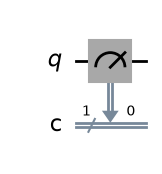

In [38]:
circuito_medida_0 = QuantumCircuit(1, 1)
circuito_medida_0.measure(0, 0)

print(circuito_medida_0)
display(circuito_medida_0.draw(output="mpl"))

# TODO: añade la medida y visualiza

### Responde

1. ¿Qué significa la flecha de medida?

    _Significa que se hace una medida sobre el qubit,baja cuando se hace la medida y que resultado se guarda en el bit clásico._
2. ¿Dónde se almacena el resultado?

    _En el bit claico c_
3. ¿Cuál debe ser el resultado?

    _Debe de ser 0, porque la proabilidad es $P(0)=1$._
4. ¿La medida es una puerta unitaria?

    _No, la medida es colapsar el estado y destruir la suerposición y la fase._



## Ejercicio 12. Medida de $|1\rangle$
Construye $|0\rangle\xrightarrow{X}|1\rangle\xrightarrow{medida}1$ y visualízalo.

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


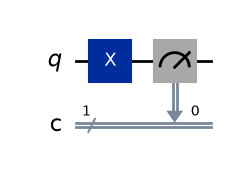

In [14]:
circuito_medida_1 = QuantumCircuit(1, 1)
circuito_medida_1.x(0)
circuito_medida_1.measure(0,0)

# TODO: aplica X, mide y visualiza
print(circuito_medida_1)
display(circuito_medida_1.draw(output="mpl"))

### Responde

1. ¿Qué operación se aplica primero?
2. ¿Cómo se identifica el orden temporal?
3. ¿Qué ocurriría si la medida apareciese antes de $X$?
4. ¿El resultado clásico sería el mismo?

**Respuesta:** TODO

## Ejercicio 13. `measure_all()`

Crea dos qubits sin bits clásicos, aplica `measure_all()`, visualiza y consulta `num_clbits`.

Bit clasicos 2
        ┌───┐ ░ ┌─┐   
   q_0: ┤ X ├─░─┤M├───
        ├───┤ ░ └╥┘┌─┐
   q_1: ┤ H ├─░──╫─┤M├
        └───┘ ░  ║ └╥┘
meas: 2/═════════╩══╩═
                 0  1 


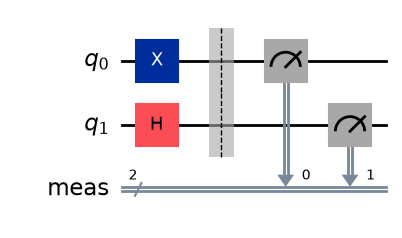

In [15]:
circuito_todos = QuantumCircuit(2)
circuito_todos.x(0)
circuito_todos.h(1)
circuito_todos.measure_all()

# TODO: mide todos los qubits, visualiza y muestra num_clbits
print("Bit clasicos", circuito_todos.num_clbits)
print(circuito_todos)
display(circuito_todos.draw(output="mpl"))

### Responde

1. ¿Qué ha añadido `measure_all()`?
2. ¿Cuántos bits clásicos aparecen?
3. ¿Qué diferencia presenta respecto a `measure(0, 0)`?
4. ¿Cuándo conviene controlar explícitamente la correspondencia?

**Respuesta:** TODO

# Parte E. Ejecución con Aer

## Ejercicio 14. Simulador y transpilación

Crea `AerSimulator()`. Transpila los circuitos de medida de $|0\rangle$ y $|1\rangle$ para ese backend y visualiza los resultados.

AerSimulator('aer_simulator')


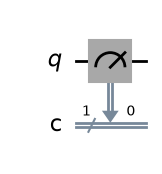

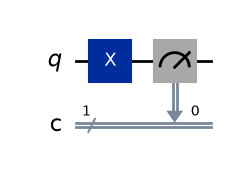

In [16]:
simulador = AerSimulator()

circuito_0_transpilado = transpile(circuito_medida_0, simulador)
circuito_1_transpilado = transpile(circuito_medida_1, simulador)

# TODO: muestra el simulador y los circuitos transpilados
print(simulador)
display(circuito_0_transpilado.draw(output="mpl"))
display(circuito_1_transpilado.draw(output="mpl"))


### Responde

1. ¿El simulador es el circuito?
2. ¿Por qué se adapta un circuito al backend?
3. ¿Qué finalidad tendrá la transpilación en hardware real?
4. ¿Un simulador ideal incorpora automáticamente ruido?

**Respuesta:** TODO

## Ejercicio 15. Ejecución de $|0\rangle$
Ejecuta 1.000 shots con `seed_simulator=42`. Recupera el trabajo, el resultado y los conteos. Comprueba la suma.

In [17]:
circuito = QuantumCircuit(1,1)
estado=Statevector.from_instruction(circuito)
print(estado.data)
circuito_0=circuito.copy()
circuito_0.measure(0,0)
print(estado.probabilities())
prob= estado.probabilities_dict()
print(f"P(0)={prob.get('0',0)}")

simulador=AerSimulator()
ciruito_0_transpilado= transpile(circuito_0,simulador)
trabajo_0 = simulador.run(circuito_0_transpilado, shots=1000, seed_simulator=42)
print(trabajo_0)
resultado_0 = trabajo_0.result()
print(resultado_0)

if resultado_0.success:
    conteos_0 = resultado_0.get_counts()
    print(conteos_0)

# TODO: muestra los objetos y comprueba el total

[1.+0.j 0.+0.j]
[1. 0.]
P(0)=1.0
Result(backend_name='aer_simulator', backend_version='0.17.2', job_id='4f7a3597-a19e-410f-8516-82c3aa757e50', success=True, results=[ExperimentResult(shots=1000, success=True, meas_level=2, data=ExperimentResultData(counts={'0x0': 1000}), header={'creg_sizes': [['c', 1]], 'global_phase': 0.0, 'memory_slots': 1, 'n_qubits': 1, 'name': 'circuit-65', 'qreg_sizes': [['q', 1]], 'metadata': {}}, status=DONE, seed_simulator=42, metadata={'batched_shots_optimization': False, 'required_memory_mb': 0, 'method': 'stabilizer', 'active_input_qubits': [0], 'device': 'CPU', 'remapped_qubits': False, 'num_qubits': 1, 'num_clbits': 1, 'time_taken': 0.0061412, 'sample_measure_time': 0.0010686, 'input_qubit_map': [[0, 0]], 'max_memory_mb': 15613, 'measure_sampling': True, 'noise': 'ideal', 'parallel_shots': 1, 'parallel_state_update': 16, 'runtime_parameter_bind': False, 'num_bind_params': 1, 'fusion': {'enabled': False}}, time_taken=0.0061412)], date=2026-10-22T01:09:03.

### Responde

1. ¿Qué representa el trabajo?
2. ¿Qué devuelve `result()`?
3. ¿Qué devuelve `get_counts()`?
4. ¿Cuánto suman los conteos?
5. ¿Por qué el resultado es determinista?

**Respuesta:** TODO

## Ejercicio 16. Ejecución de $|1\rangle$
Ejecuta 10, 100, 1.000 y 10.000 shots. Para cada caso calcula conteos y frecuencias.

In [18]:
shots_estudiados_determinista = [10, 100, 1_000, 10_000]
resultados_deterministas = []

# TODO: ejecuta el circuito para cada número de shots
# Usa conteos.get("0", 0) y conteos.get("1", 0)

### Responde

1. ¿Por qué conviene utilizar `get()`?
2. ¿Cambia la distribución al aumentar los shots?
3. ¿Aporta información nueva usar 10.000 shots en este caso?
4. ¿Aparece incertidumbre estadística en el simulador ideal?

**Respuesta:** TODO

# Parte F. Conteos e histogramas

## Ejercicio 17. Función de ejecución

Implementa una función que valide `shots`, transpile, ejecute y devuelva conteos.

In [19]:
def ejecutar_con_shots(circuito, shots=1000, semilla=42):
    """Transpila y ejecuta un circuito con medidas."""
    # TODO
    pass


# TODO: prueba la función con |0> y |1>

## Ejercicio 18. Frecuencias

Implementa una función que convierta conteos en frecuencias y rechace diccionarios vacíos, conteos negativos, no enteros o con total cero.

In [20]:
def calcular_frecuencias(conteos):
    """Convierte un diccionario de conteos en frecuencias relativas."""
    # TODO
    pass


# TODO: prueba con {"0": 250, "1": 750}

### Responde

1. ¿Qué diferencia existe entre conteo y frecuencia?
2. ¿Qué deben sumar las frecuencias?
3. ¿Equivale una frecuencia a una amplitud?
4. ¿Puede recuperarse el signo de una amplitud a partir de conteos?

**Respuesta:** TODO

## Ejercicio 19. Histogramas
Representa por separado los conteos de $|0\rangle$ y $|1\rangle$ y después ambos en una misma figura con leyenda.

In [21]:
# TODO: genera tres histogramas con plot_histogram()

### Responde

1. ¿Qué información representa el histograma?
2. ¿Muestra el circuito o el vector de estado?
3. ¿Muestra amplitudes o fases?

**Respuesta:** TODO

# Parte G. Simulación exacta y muestreo

## Ejercicio 20. Primera superposición

Crea un circuito con una puerta $H$, obtén su vector y compáralo con $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$. Muestra probabilidades exactas.

In [22]:
circuito_plus = QuantumCircuit(1)

# TODO: aplica H

estado_plus = ...
ket_plus_numpy = np.array([1 / np.sqrt(2), 1 / np.sqrt(2)], dtype=complex)

# TODO: muestra y compara amplitudes y probabilidades

## Ejercicio 21. Medida de la superposición

Crea una copia, añade medidas y ejecútala con 10, 100, 1.000 y 10.000 shots. Calcula $f(0)$, $f(1)$ y $|f(0)-1/2|$.

In [23]:
circuito_plus_medida = circuito_plus.copy()

# TODO: añade medidas

shots_superposicion = [10, 100, 1_000, 10_000]
resultados_superposicion = []

# TODO: ejecuta y almacena shots, conteos, frecuencias y error

### Responde

1. ¿Coinciden exactamente frecuencias y probabilidades?
2. ¿Qué sucede normalmente al aumentar los shots?
3. ¿Debe disminuir estrictamente el error en cada fila?
4. ¿Qué diferencia hay respecto a $|0\rangle$ y $|1\rangle$?
5. ¿Se conserva la fase en los conteos?

**Respuesta:** TODO

## Ejercicio 22. Gráfica de convergencia

Representa shots frente a frecuencia de 0, con eje horizontal logarítmico y una línea teórica en 0,5. Interpreta la gráfica.

In [24]:
# TODO: extrae los datos y crea la gráfica completa

**Interpretación:** TODO

## Ejercicio 23. Comparación exacta y experimental

Con 10.000 shots, construye una tabla con resultado, amplitud, probabilidad exacta, conteo y frecuencia.

In [25]:
# TODO: construye y muestra la tabla comparativa

### Responde

1. ¿Qué columnas proceden de `Statevector`?
2. ¿Cuáles requieren medida?
3. ¿Cuál conserva información de fase?
4. ¿Por qué los conteos no reconstruyen el estado completo?

**Respuesta:** TODO

# Parte H. Circuitos de dos qubits

## Ejercicio 24. Estado inicial

Crea dos qubits, obtén el vector y el diccionario de probabilidades, y comprueba que representan $|00\rangle$.

|00>
[]
[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
1.0
0.0
0.0
0.0
P(|00>)=1.0


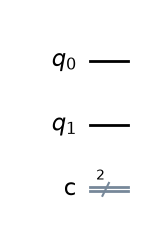

|01>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=())]
[0.+0.j 1.+0.j 0.+0.j 0.+0.j]
0.0
1.0
0.0
0.0
P(|01>)=1.0


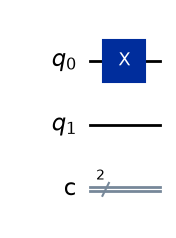

|10>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=())]
[0.+0.j 0.+0.j 1.+0.j 0.+0.j]
0.0
0.0
1.0
0.0
P(|10>)=1.0


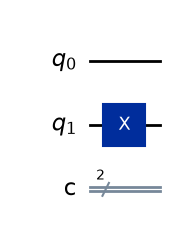

|11>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=()), CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=())]
[0.+0.j 0.+0.j 0.+0.j 1.+0.j]
0.0
0.0
0.0
1.0
P(|11>)=1.0


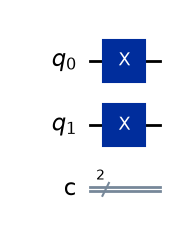

In [26]:
circuito_00 = QuantumCircuit(2,2)
circuito_01=QuantumCircuit(2,2)
circuito_01.x(0)

circuito_10=QuantumCircuit(2,2)
circuito_10.x(1)

circuito_11=QuantumCircuit(2,2)
circuito_11.x(0)
circuito_11.x(1)

circuitos={
    "00": circuito_00,
    "01": circuito_01,
    "10": circuito_10,
    "11": circuito_11
}
# estado_00 = 

for k, circuito in circuitos.items():
    print(f"|{k}>")
    info=circuito.data
    print(info)
    estado=Statevector.from_instruction(circuito)
    amp= estado.data
    print(amp)
    # una forma
    prob=estado.probabilities()
    for p in prob:
        print(p)

    prob_dir=estado.probabilities_dict()
    for x,p in prob_dir.items():
        print(f"P(|{x}>)={p}")
    display(circuito.draw(output="mpl"))

# TODO: muestra vector, dimensión y probabilidades

### Responde

1. ¿Cuántas amplitudes contiene?
2. ¿Por qué son cuatro?
3. ¿Cuál es el orden de la base?
4. ¿Qué dimensión tendrá un estado de tres qubits?

**Respuesta:** TODO

## Ejercicio 25. Base computacional de dos qubits
Construye circuitos para $|00\rangle$, $|01\rangle$, $|10\rangle$ y $|11\rangle$. Dibuja cada uno y muestra su vector y `probabilities_dict()`.

In [27]:
# TODO: construye los cuatro circuitos
circuitos_base_2q = {
    "|00>": circuito_00,
    # Completa el diccionario
}

# TODO: visualiza y analiza todos los circuitos

## Ejercicio 26. Orden de bits

Aplica `x(0)` a dos qubits. Muestra el vector y el diccionario de probabilidades.

In [28]:
circuito_orden = QuantumCircuit(2)

# TODO: aplica X a q_0 y analiza el estado

### Responde

1. ¿Por qué aparece `"01"` y no `"10"`?
2. ¿Qué valores tienen $q_0$ y $q_1$?
3. ¿En qué orden se muestran las cadenas?
4. ¿Cuál es el orden del vector de amplitudes?

**Respuesta:** TODO

## Ejercicio 27. Medida de dos qubits

Para los cuatro estados de la base, crea copias con dos bits clásicos, mide cada qubit en el bit del mismo índice y ejecuta 1.000 shots.

In [29]:
conteos_base_2q = {}

# TODO: añade medidas, ejecuta y almacena conteos para los cuatro estados

## Ejercicio 28. Intercambio de bits clásicos
Prepara $|01\rangle$ y compara la medida directa `q0→c0, q1→c1` con la medida intercambiada `q0→c1, q1→c0`.

In [30]:
# TODO: crea y ejecuta ambos circuitos

### Responde

1. ¿Cambia el estado anterior a la medida?
2. ¿Cambia la cadena clásica?
3. ¿Qué demuestra el experimento?
4. ¿Por qué debe revisarse el mapeo entre qubits y bits?

**Respuesta:** TODO

# Parte I. Interpretación conceptual

## Ejercicio 29. Clasificación

Clasifica y justifica: `QuantumCircuit(2,2)`, `Statevector.from_instruction(c)`, `estado.data`, `estado.probabilities()`, `measure()`, `"01"`, `{"00":492,"11":508}`, `492/1000`, `plot_histogram()` y `simulador.run()`.

**Respuesta:** TODO

## Ejercicio 30. Verdadero o falso

Justifica:

1. Crear un circuito lo ejecuta inmediatamente.
2. Los qubits comienzan por defecto en $|0\rangle$.
3. Un bit clásico puede contener una superposición.
4. Declarar bits clásicos añade medidas.
5. `Statevector.data` contiene amplitudes.
6. `probabilities_dict()` devuelve conteos.
7. Cada shot incluye una nueva preparación.
8. El histograma muestra amplitudes.
9. La transpilación adapta el circuito al backend.
10. Dos circuitos distintos pueden producir el mismo estado final.
11. Probabilidades iguales implican amplitudes iguales.
12. Qiskit muestra $q_0$ a la izquierda de las cadenas.
13. `x(0)` sobre dos qubits prepara $|01\rangle$.
14. Un simulador ideal incluye ruido automáticamente.
15. La medida puede eliminar información de fase.

**Respuesta:** TODO

# Reto avanzado. Analizador de circuitos

Implementa una función que reciba un circuito sin medidas y devuelva el vector, probabilidades exactas, una copia con medidas, conteos y frecuencias. Debe validar el tipo, los shots y que el circuito no contenga medidas.

In [31]:
def analizar_circuito(circuito_sin_medidas, shots=1000, semilla=42):
    """Analiza exactamente un circuito y simula después sus medidas."""
    # TODO
    pass


# TODO: pruébala con circuitos vacío, X, XX, H y |01>

### Responde

1. ¿Qué parte es exacta?
2. ¿Qué parte depende de los shots?
3. ¿Qué información desaparece en los conteos?
4. ¿Por qué se conserva el circuito original sin medidas?
5. ¿Cómo comprobarías la coherencia entre conteos y shots?

**Respuesta:** TODO

# Pruebas mínimas

Descomenta estas pruebas al completar la práctica y añade casos inválidos.

In [32]:
# assert circuito_0.num_qubits == 1
# assert circuito_0.num_clbits == 0
# assert np.allclose(estado_0.data, [1, 0])
# assert np.allclose(estado_1.data, [0, 1])
# assert np.allclose(estado_xx.data, [1, 0])
# assert np.allclose(X_numpy @ ket_0_numpy, estado_1.data)
# assert sum(conteos_0.values()) == 1000
# assert conteos_0.get("0", 0) == 1000
# assert np.allclose(estado_plus.probabilities(), [0.5, 0.5])

# TODO: añade pruebas de frecuencias, dos qubits, shots inválidos,
# conteos inválidos y conservación del circuito original